# Train a Devanagari Handwritten Character CNN

This notebook trains a 46-class CNN from the `DevanagariHandwrittenCharacterDataset` folder and saves a checkpoint compatible with the project's `backend/app/services/model_adapter.py`.

**Expected project layout**
```text
devanagari-ocr-translation/
├── DevanagariHandwrittenCharacterDataset/
│   ├── Train/                 # one subfolder per class
│   │   ├── character_10_yna/
│   │   ├── character_11_taamatar/
│   │   └── ...
│   └── Test/                  # one subfolder per class (recommended)
└── backend/
    ├── app/services/model_adapter.py
    └── models/
```

The notebook also supports class folders directly under the dataset folder, but a separate test split is strongly recommended. It uses the same CNN layer names and input size as the current backend. The saved checkpoint contains `model_state_dict`, `num_classes`, `class_names`, `test_accuracy`, and `history`.

> Important: 46-class accuracy measures isolated-character recognition, not full-page handwritten OCR. Full-page OCR still needs reliable line/character segmentation and handling of vowel signs and conjuncts.

## 1. Install/import dependencies
Run this in the notebook's Python environment. If using the project's `.venv`, install missing packages there.

In [1]:
%pip install torch torchvision pillow numpy matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import os
import random
import time
import copy
import json

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from sklearn.metrics import classification_report, confusion_matrix

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cpu


## 2. Set dataset and output paths
The notebook can be run from the repository root or from `backend/`. Adjust `PROJECT_ROOT` manually if automatic detection does not find the dataset.

In [3]:
# Try common locations relative to the current notebook working directory.
CWD = Path.cwd()
candidate_roots = [
    CWD,
    CWD.parent,
    CWD.parent.parent,
]

DATASET_DIR = None
PROJECT_ROOT = None
for root in candidate_roots:
    candidate = root / "DevanagariHandwrittenCharacterDataset"
    if candidate.is_dir():
        DATASET_DIR = candidate.resolve()
        PROJECT_ROOT = root.resolve()
        break

if DATASET_DIR is None:
    # EDIT THIS if your notebook is stored somewhere else:
    PROJECT_ROOT = Path(r"C:\Users\soham\OneDrive\Desktop\Codes\DL Project\devanagari-ocr-translation")
    DATASET_DIR = PROJECT_ROOT / "DevanagariHandwrittenCharacterDataset"

OUTPUT_DIR = PROJECT_ROOT / "backend" / "models"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_PATH = OUTPUT_DIR / "devanagari_cnn_best.pth"

print("Project root :", PROJECT_ROOT)
print("Dataset      :", DATASET_DIR)
print("Output model :", CHECKPOINT_PATH)
assert DATASET_DIR.is_dir(), f"Dataset folder not found: {DATASET_DIR}. Edit DATASET_DIR above."

Project root : C:\Users\soham\OneDrive\Desktop\Codes\DL Project\devanagari-ocr-translation
Dataset      : C:\Users\soham\OneDrive\Desktop\Codes\DL Project\devanagari-ocr-translation\DevanagariHandwrittenCharacterDataset
Output model : C:\Users\soham\OneDrive\Desktop\Codes\DL Project\devanagari-ocr-translation\backend\models\devanagari_cnn_best.pth


## 3. Detect dataset structure
Supported layouts include `Train/class_name/*.png` and `Test/class_name/*.png`. If only one class-folder tree exists, the notebook will make a reproducible train/validation split.

In [4]:
def is_class_folder_tree(path: Path) -> bool:
    if not path.is_dir():
        return False
    class_dirs = [p for p in path.iterdir() if p.is_dir()]
    return len(class_dirs) >= 2 and any(
        any(f.suffix.lower() in {".png", ".jpg", ".jpeg", ".bmp"} for f in d.iterdir() if f.is_file())
        for d in class_dirs
    )

train_candidates = [DATASET_DIR / "Train", DATASET_DIR / "train"]
test_candidates = [DATASET_DIR / "Test", DATASET_DIR / "test"]
train_dir = next((p for p in train_candidates if is_class_folder_tree(p)), None)
test_dir = next((p for p in test_candidates if is_class_folder_tree(p)), None)

if train_dir is None and is_class_folder_tree(DATASET_DIR):
    train_dir = DATASET_DIR

print("Train folder:", train_dir)
print("Test folder :", test_dir)
if train_dir is None:
    raise RuntimeError(
        "Could not find class subfolders. Expected Dataset/Train/class_name/images "
        "or Dataset/class_name/images. Inspect DATASET_DIR and edit the path/layout."
    )

IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp"}
class_names = sorted([p.name for p in train_dir.iterdir() if p.is_dir()])
print("Classes found:", len(class_names))
print("First classes:", class_names[:10])

if len(class_names) != 46:
    raise ValueError(
        f"Expected 46 class folders for the current backend, found {len(class_names)}. "
        "Check that the correct dataset variant is selected; do not save a checkpoint "
        "with a different class count unless you also update the backend."
    )

if test_dir is not None:
    test_class_names = sorted([p.name for p in test_dir.iterdir() if p.is_dir()])
    if test_class_names != class_names:
        raise ValueError("Train and Test class folder names do not match exactly.")

Train folder: C:\Users\soham\OneDrive\Desktop\Codes\DL Project\devanagari-ocr-translation\DevanagariHandwrittenCharacterDataset\Train
Test folder : C:\Users\soham\OneDrive\Desktop\Codes\DL Project\devanagari-ocr-translation\DevanagariHandwrittenCharacterDataset\Test
Classes found: 46
First classes: ['character_10_yna', 'character_11_taamatar', 'character_12_thaa', 'character_13_daa', 'character_14_dhaa', 'character_15_adna', 'character_16_tabala', 'character_17_tha', 'character_18_da', 'character_19_dha']


## 4. Create transforms and datasets
Images are converted to grayscale and resized to 32×32. The normalization matches the current backend's `preprocess_character` output range of `[-1, 1]`. Mild augmentation is applied only to training images.

In [5]:
IMAGE_SIZE = 32
BATCH_SIZE = 128
NUM_WORKERS = 0  # reliable on Windows/Jupyter

train_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomAffine(
        degrees=7,
        translate=(0.06, 0.06),
        scale=(0.90, 1.10),
        shear=4,
        fill=255,
    ),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
])

eval_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
])

if test_dir is not None:
    # Keep the provided Test folder completely held out for final evaluation.
    train_full_aug = datasets.ImageFolder(train_dir, transform=train_transform)
    train_full_eval = datasets.ImageFolder(train_dir, transform=eval_transform)
    test_dataset = datasets.ImageFolder(test_dir, transform=eval_transform)

    if train_full_aug.classes != test_dataset.classes:
        raise ValueError("Train and Test class mappings do not match.")

    val_size = max(1, int(0.10 * len(train_full_aug)))
    train_size = len(train_full_aug) - val_size
    split_generator = torch.Generator().manual_seed(SEED)
    train_subset, val_subset_aug = random_split(
        train_full_aug, [train_size, val_size], generator=split_generator
    )
    # Validation uses the exact same held-out indices but deterministic transforms.
    val_dataset = copy.copy(val_subset_aug)
    val_dataset.dataset = train_full_eval
    train_dataset = train_subset
else:
    train_full_aug = datasets.ImageFolder(train_dir, transform=train_transform)
    train_full_eval = datasets.ImageFolder(train_dir, transform=eval_transform)
    val_size = max(1, int(0.15 * len(train_full_aug)))
    train_size = len(train_full_aug) - val_size
    split_generator = torch.Generator().manual_seed(SEED)
    train_subset, val_subset_aug = random_split(
        train_full_aug, [train_size, val_size], generator=split_generator
    )
    val_dataset = copy.copy(val_subset_aug)
    val_dataset.dataset = train_full_eval
    train_dataset = train_subset
    test_dataset = None

print("Training images  :", len(train_dataset))
print("Validation images:", len(val_dataset))
if test_dataset is not None:
    print("Test images      :", len(test_dataset))

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda")
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda")
)
if test_dataset is not None:
    test_loader = DataLoader(
        test_dataset, batch_size=BATCH_SIZE, shuffle=False,
        num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda")
    )

Training images  : 4140
Validation images: 460
Test images      : 4600


## 5. Inspect sample images
Confirm the dataset looks correct before training.

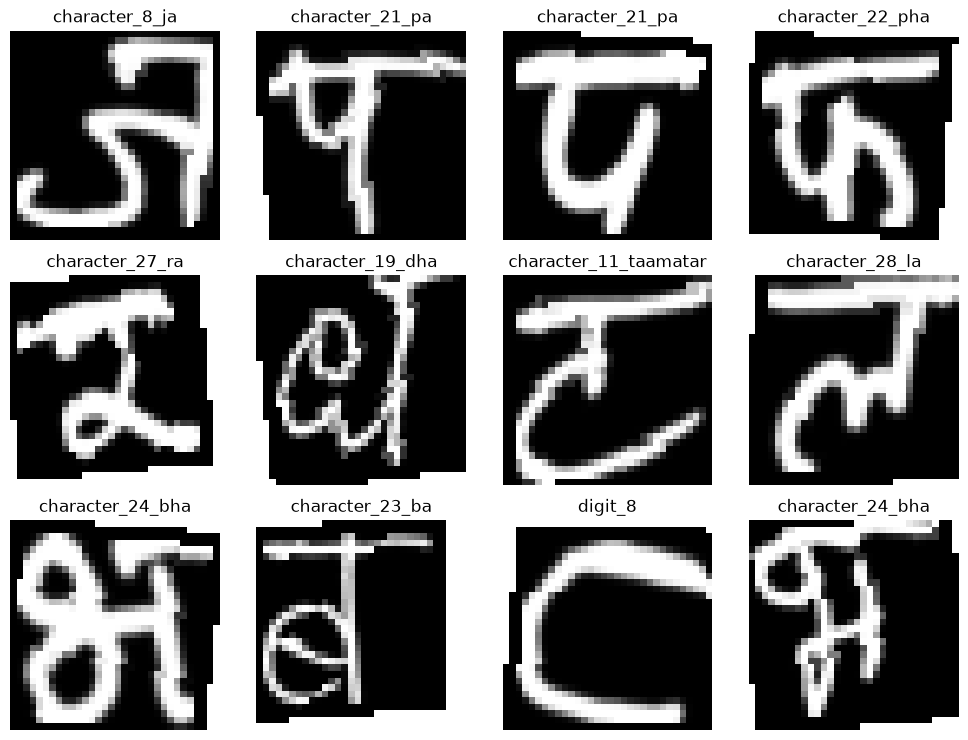

In [6]:
def show_batch(loader, names, count=12):
    images, labels = next(iter(loader))
    count = min(count, len(images))
    cols = 4
    rows = int(np.ceil(count / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(10, 2.5 * rows))
    axes = np.array(axes).reshape(-1)
    for i in range(count):
        img = images[i].squeeze(0).cpu().numpy()
        img = img * 0.5 + 0.5
        axes[i].imshow(img, cmap="gray", vmin=0, vmax=1)
        axes[i].set_title(names[int(labels[i])])
        axes[i].axis("off")
    for i in range(count, len(axes)):
        axes[i].axis("off")
    plt.tight_layout()

show_batch(train_loader, class_names)

## 6. Define the CNN
This architecture intentionally preserves the exact module names and layer shapes used by the backend's existing `DevanagariCNN`, so its state dictionary can be loaded without changing `model_adapter.py`.

In [7]:
class DevanagariCNN(nn.Module):
    def __init__(self, num_classes=46):
        super().__init__()
        self.conv1a = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.bn1a = nn.BatchNorm2d(32)
        self.conv1b = nn.Conv2d(32, 32, kernel_size=3, padding=1)
        self.bn1b = nn.BatchNorm2d(32)
        self.pool1 = nn.MaxPool2d(2, 2)
        self.drop1 = nn.Dropout2d(0.25)

        self.conv2a = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2a = nn.BatchNorm2d(64)
        self.conv2b = nn.Conv2d(64, 64, kernel_size=3, padding=1)
        self.bn2b = nn.BatchNorm2d(64)
        self.pool2 = nn.MaxPool2d(2, 2)
        self.drop2 = nn.Dropout2d(0.25)

        self.conv3a = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3a = nn.BatchNorm2d(128)
        self.conv3b = nn.Conv2d(128, 128, kernel_size=3, padding=1)
        self.bn3b = nn.BatchNorm2d(128)
        self.pool3 = nn.MaxPool2d(2, 2)
        self.drop3 = nn.Dropout2d(0.25)

        self.fc1 = nn.Linear(128 * 4 * 4, 256)
        self.bn_fc = nn.BatchNorm1d(256)
        self.drop_fc = nn.Dropout(0.5)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = F.relu(self.bn1a(self.conv1a(x)))
        x = F.relu(self.bn1b(self.conv1b(x)))
        x = self.drop1(self.pool1(x))
        x = F.relu(self.bn2a(self.conv2a(x)))
        x = F.relu(self.bn2b(self.conv2b(x)))
        x = self.drop2(self.pool2(x))
        x = F.relu(self.bn3a(self.conv3a(x)))
        x = F.relu(self.bn3b(self.conv3b(x)))
        x = self.drop3(self.pool3(x))
        x = torch.flatten(x, start_dim=1)
        x = F.relu(self.bn_fc(self.fc1(x)))
        x = self.drop_fc(x)
        return self.fc2(x)

model = DevanagariCNN(num_classes=len(class_names)).to(DEVICE)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

Parameters: 824,206


## 7. Train the model
Training runs on CUDA if available; otherwise CPU. The best checkpoint is selected by validation accuracy (or training-loss fallback when there is no separate test folder). Adjust `EPOCHS` if needed.

In [8]:
EPOCHS = 20
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
PATIENCE = 5

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(
    model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=2
)

def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        if training:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            logits = model(images)
            loss = criterion(logits, labels)
            if training:
                loss.backward()
                optimizer.step()
        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        correct += (logits.argmax(1) == labels).sum().item()
        total += batch_size
    return total_loss / max(total, 1), correct / max(total, 1)

history = {
    "train_loss": [], "train_accuracy": [],
    "validation_loss": [], "validation_accuracy": []
}
best_score = -1.0
best_state = None
epochs_without_improvement = 0
start_time = time.time()

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = run_epoch(model, train_loader, optimizer)
    val_loss, val_acc = run_epoch(model, val_loader)
    scheduler.step(val_acc)

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_acc)
    history["validation_loss"].append(val_loss)
    history["validation_accuracy"].append(val_acc)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"train loss {train_loss:.4f}, acc {train_acc:.4%} | "
        f"val loss {val_loss:.4f}, acc {val_acc:.4%}"
    )

    if val_acc > best_score:
        best_score = val_acc
        best_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping: validation accuracy did not improve.")
        break

if best_state is not None:
    model.load_state_dict(best_state)

print(f"Training time: {(time.time() - start_time) / 60:.1f} minutes")

Epoch 01/20 | train loss 3.5281, acc 12.0048% | val loss 2.9965, acc 21.3043%
Epoch 02/20 | train loss 2.5885, acc 36.0628% | val loss 1.8224, acc 57.3913%
Epoch 03/20 | train loss 1.9163, acc 53.6957% | val loss 1.3505, acc 72.1739%
Epoch 04/20 | train loss 1.4442, acc 64.5894% | val loss 0.9345, acc 80.0000%
Epoch 05/20 | train loss 1.0997, acc 73.4300% | val loss 0.6508, acc 85.8696%
Epoch 06/20 | train loss 0.8883, acc 78.6715% | val loss 0.5008, acc 88.4783%
Epoch 07/20 | train loss 0.7244, acc 81.9324% | val loss 0.4327, acc 88.9130%
Epoch 08/20 | train loss 0.6214, acc 84.1304% | val loss 0.3433, acc 92.3913%
Epoch 09/20 | train loss 0.5275, acc 87.1739% | val loss 0.2997, acc 92.8261%
Epoch 10/20 | train loss 0.4672, acc 87.8502% | val loss 0.2695, acc 93.2609%
Epoch 11/20 | train loss 0.4192, acc 89.3720% | val loss 0.2368, acc 93.4783%
Epoch 12/20 | train loss 0.3682, acc 90.6522% | val loss 0.2387, acc 93.6957%
Epoch 13/20 | train loss 0.3383, acc 91.4010% | val loss 0.2150,

## 8. Plot training history

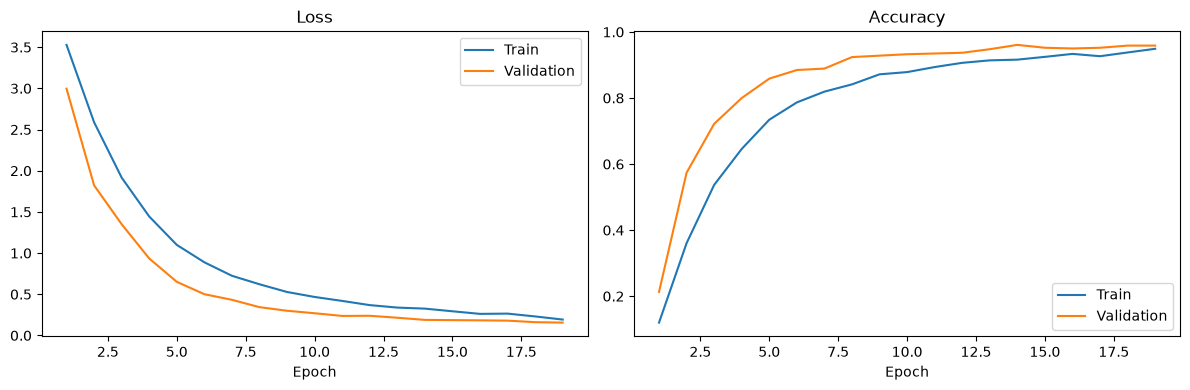

In [9]:
epochs_ran = range(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs_ran, history["train_loss"], label="Train")
if val_dataset is not None:
    axes[0].plot(epochs_ran, history["validation_loss"], label="Validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[1].plot(epochs_ran, history["train_accuracy"], label="Train")
if val_dataset is not None:
    axes[1].plot(epochs_ran, history["validation_accuracy"], label="Validation")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()
plt.tight_layout()

## 9. Evaluate on the separate test set
If your dataset has a `Test` folder, this cell reports held-out test accuracy. If no test folder exists, it reports validation results from the random split.

In [10]:
evaluation_loader = test_loader if test_dataset is not None else val_loader
evaluation_name = "Test" if test_dataset is not None else "Validation"
test_loss, final_accuracy = run_epoch(model, evaluation_loader)
print(f"{evaluation_name} loss    : {test_loss:.4f}")
print(f"{evaluation_name} accuracy: {final_accuracy:.4%}")

all_true, all_pred = [], []
model.eval()
with torch.inference_mode():
    for images, labels in evaluation_loader:
        logits = model(images.to(DEVICE))
        all_pred.extend(logits.argmax(1).cpu().tolist())
        all_true.extend(labels.tolist())

print(classification_report(
    all_true, all_pred, labels=list(range(len(class_names))),
    target_names=class_names, zero_division=0
))

Test loss    : 0.1521
Test accuracy: 96.1739%
                           precision    recall  f1-score   support

         character_10_yna       0.99      0.98      0.98       100
    character_11_taamatar       0.98      0.98      0.98       100
        character_12_thaa       0.98      0.98      0.98       100
         character_13_daa       0.98      0.96      0.97       100
        character_14_dhaa       0.92      0.98      0.95       100
        character_15_adna       0.98      0.98      0.98       100
      character_16_tabala       0.93      0.99      0.96       100
         character_17_tha       0.86      0.94      0.90       100
          character_18_da       0.91      0.93      0.92       100
         character_19_dha       0.91      0.92      0.92       100
           character_1_ka       0.96      0.99      0.98       100
          character_20_na       0.92      0.93      0.93       100
          character_21_pa       0.96      0.94      0.95       100
         charac

## 10. Save the project-compatible `.pth` checkpoint
This saves the best model to `backend/models/devanagari_cnn_best.pth`, the path already configured in the backend. A backup is made if a checkpoint already exists.

In [11]:
if CHECKPOINT_PATH.exists():
    backup_path = CHECKPOINT_PATH.with_name(
        f"{CHECKPOINT_PATH.stem}_backup_{time.strftime('%Y%m%d_%H%M%S')}{CHECKPOINT_PATH.suffix}"
    )
    import shutil
    shutil.copy2(CHECKPOINT_PATH, backup_path)
    print("Previous checkpoint backed up to:", backup_path)

checkpoint = {
    "model_state_dict": model.state_dict(),
    "num_classes": len(class_names),
    "class_names": class_names,
    "test_accuracy": float(final_accuracy),
    "history": history,
    "image_size": IMAGE_SIZE,
    "architecture": "DevanagariCNN",
    "seed": SEED,
}
torch.save(checkpoint, CHECKPOINT_PATH)
print("Saved checkpoint:", CHECKPOINT_PATH)
print("Checkpoint size :", f"{CHECKPOINT_PATH.stat().st_size / (1024 * 1024):.2f} MB")

Saved checkpoint: C:\Users\soham\OneDrive\Desktop\Codes\DL Project\devanagari-ocr-translation\backend\models\devanagari_cnn_best.pth
Checkpoint size : 3.17 MB


## 11. Verify checkpoint compatibility
This reloads the saved checkpoint using the same architecture and checks all 46 class labels are present.

In [12]:
loaded = torch.load(CHECKPOINT_PATH, map_location="cpu", weights_only=True)
assert loaded["num_classes"] == 46
assert len(loaded["class_names"]) == 46
assert "model_state_dict" in loaded
assert "test_accuracy" in loaded
verification_model = DevanagariCNN(num_classes=loaded["num_classes"])
verification_model.load_state_dict(loaded["model_state_dict"], strict=True)
verification_model.eval()
print("Checkpoint verification passed.")
print("Classes:", len(loaded["class_names"]))
print("Evaluation accuracy:", f"{loaded['test_accuracy']:.4%}")
print("Backend target:", CHECKPOINT_PATH)

Checkpoint verification passed.
Classes: 46
Evaluation accuracy: 96.1739%
Backend target: C:\Users\soham\OneDrive\Desktop\Codes\DL Project\devanagari-ocr-translation\backend\models\devanagari_cnn_best.pth


## 12. Next steps in the backend

1. Confirm the file exists at `backend/models/devanagari_cnn_best.pth`.
2. Restart FastAPI so it reloads the new checkpoint.
3. Test a single isolated character first, then test the full handwritten page.
4. Keep the output warning that the CNN is trained on isolated characters. A higher isolated-character score does not guarantee good full-page OCR.

**Preprocessing caution:** the backend applies its own crop, inversion, autocontrast and 32×32 resizing. This notebook trains on grayscale 32×32 images with normalization to `[-1, 1]`. If predictions worsen after retraining, compare the notebook's displayed training samples with the backend's `preprocess_character` output and align the two pipelines before concluding that the model is worse.